# Notebook 03 — Churn Prediction

## Objective

The objective of this notebook is to predict which active customers are
most likely to lapse during the next quarter.

The model will:

- Define churn using a fixed observation cutoff.
- Build features using only information available on or before the cutoff.
- Predict whether an eligible customer places no order during the outcome window.
- Compare an interpretable Logistic Regression baseline with a tree-based model.
- Evaluate models using ROC-AUC, PR-AUC, recall, precision and lift.
- Select a retention threshold using the provided economic assumptions.
- Identify the major drivers of churn.
- Produce customer-level churn probabilities for retention targeting.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.inspection import permutation_importance

In [4]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"

FIGURES_PATH = PROJECT_ROOT / "outputs" / "figures" / "churn"
TABLES_PATH = PROJECT_ROOT / "outputs" / "tables"

PROCESSED_DATA_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DATA_PATH)
print("Processed data:", PROCESSED_DATA_PATH)

Project root: C:\Users\Sejal patil\OneDrive\Documents\meridian_customer_analytics
Raw data: C:\Users\Sejal patil\OneDrive\Documents\meridian_customer_analytics\data\raw
Processed data: C:\Users\Sejal patil\OneDrive\Documents\meridian_customer_analytics\data\processed


In [5]:
customers = pd.read_csv(
    RAW_DATA_PATH / "customers.csv",
    parse_dates=["signup_date"]
)

products = pd.read_csv(
    RAW_DATA_PATH / "products.csv"
)

stores = pd.read_csv(
    RAW_DATA_PATH / "stores.csv"
)

transactions = pd.read_csv(
    RAW_DATA_PATH / "transactions.csv",
    parse_dates=["order_datetime", "order_date"]
)

digital_engagement = pd.read_csv(
    RAW_DATA_PATH / "digital_engagement.csv",
    parse_dates=["year_month"]
)

support_tickets = pd.read_csv(
    RAW_DATA_PATH / "support_tickets.csv",
    parse_dates=["created_at"]
)

churn_labels = pd.read_csv(
    RAW_DATA_PATH / "churn_labels.csv",
    parse_dates=["observation_cutoff", "outcome_window_end"]
)

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [6]:
CUTOFF_DATE = pd.Timestamp("2026-04-30 23:59:59")

OUTCOME_START = pd.Timestamp("2026-05-01 00:00:00")
OUTCOME_END = pd.Timestamp("2026-07-31 23:59:59")

print("Observation cutoff:", CUTOFF_DATE)
print("Outcome window:", OUTCOME_START.date(), "to", OUTCOME_END.date())

Observation cutoff: 2026-04-30 23:59:59
Outcome window: 2026-05-01 to 2026-07-31


In [7]:
transactions_before_cutoff = transactions[
    transactions["order_datetime"] <= CUTOFF_DATE
].copy()

digital_before_cutoff = digital_engagement[
    digital_engagement["year_month"] <= CUTOFF_DATE
].copy()

support_before_cutoff = support_tickets[
    support_tickets["created_at"] <= CUTOFF_DATE
].copy()

print("Transactions before cutoff:", len(transactions_before_cutoff))
print("Digital records before cutoff:", len(digital_before_cutoff))
print("Support tickets before cutoff:", len(support_before_cutoff))

Transactions before cutoff: 494946
Digital records before cutoff: 137946
Support tickets before cutoff: 9100


In [8]:
assert transactions_before_cutoff["order_datetime"].max() <= CUTOFF_DATE
assert digital_before_cutoff["year_month"].max() <= CUTOFF_DATE
assert support_before_cutoff["created_at"].max() <= CUTOFF_DATE

print("Leakage validation passed.")

Leakage validation passed.


In [9]:
lifetime_orders = (
    transactions_before_cutoff
    .groupby("customer_id")["order_id"]
    .nunique()
    .rename("lifetime_orders")
)

six_month_start = CUTOFF_DATE - pd.DateOffset(months=6)

recent_6m_orders = (
    transactions_before_cutoff[
        transactions_before_cutoff["order_datetime"] >= six_month_start
    ]
    .groupby("customer_id")["order_id"]
    .nunique()
    .rename("orders_last_6m")
)

In [10]:
eligibility = pd.concat(
    [lifetime_orders, recent_6m_orders],
    axis=1
).fillna(0)

eligible_customers = eligibility[
    (eligibility["lifetime_orders"] >= 2) &
    (eligibility["orders_last_6m"] >= 1)
].index

print("Eligible customers:", len(eligible_customers))

Eligible customers: 7247


In [11]:
outcome_transactions = transactions[
    (transactions["order_datetime"] >= OUTCOME_START) &
    (transactions["order_datetime"] <= OUTCOME_END)
].copy()

future_orders = (
    outcome_transactions
    .groupby("customer_id")["order_id"]
    .nunique()
    .rename("future_orders")
)

churn_dataset = pd.DataFrame({
    "customer_id": eligible_customers
})

churn_dataset = churn_dataset.merge(
    future_orders,
    on="customer_id",
    how="left"
)

churn_dataset["future_orders"] = (
    churn_dataset["future_orders"]
    .fillna(0)
)

churn_dataset["churned"] = (
    churn_dataset["future_orders"] == 0
).astype(int)

In [12]:
churn_rate = churn_dataset["churned"].mean()

print("Eligible customers:", len(churn_dataset))
print("Churned customers:", churn_dataset["churned"].sum())
print("Churn rate:", round(churn_rate * 100, 2), "%")

Eligible customers: 7247
Churned customers: 1678
Churn rate: 23.15 %


In [13]:
cutoff_transactions = transactions_before_cutoff[
    transactions_before_cutoff["customer_id"].isin(eligible_customers)
].copy()

In [14]:
last_order = (
    cutoff_transactions
    .groupby("customer_id")["order_datetime"]
    .max()
    .rename("last_order_datetime")
)

rfm = pd.DataFrame({
    "customer_id": eligible_customers
}).merge(
    last_order,
    on="customer_id",
    how="left"
)

rfm["recency_days"] = (
    CUTOFF_DATE - rfm["last_order_datetime"]
).dt.total_seconds() / (24 * 60 * 60)

In [15]:
frequency = (
    cutoff_transactions
    .groupby("customer_id")["order_id"]
    .nunique()
    .rename("frequency")
)

rfm = rfm.merge(
    frequency,
    on="customer_id",
    how="left"
)

In [16]:
monetary = (
    cutoff_transactions
    .groupby("customer_id")["line_revenue_aed"]
    .sum()
    .rename("monetary")
)

rfm = rfm.merge(
    monetary,
    on="customer_id",
    how="left"
)

In [17]:
order_values = (
    cutoff_transactions
    .groupby(["customer_id", "order_id"])["line_revenue_aed"]
    .sum()
    .reset_index()
)

aov = (
    order_values
    .groupby("customer_id")["line_revenue_aed"]
    .mean()
    .rename("average_order_value")
)

rfm = rfm.merge(
    aov,
    on="customer_id",
    how="left"
)

In [18]:
last_90_start = CUTOFF_DATE - pd.Timedelta(days=90)
previous_90_start = CUTOFF_DATE - pd.Timedelta(days=180)

last_90 = cutoff_transactions[
    cutoff_transactions["order_datetime"] >= last_90_start
].copy()

previous_90 = cutoff_transactions[
    (cutoff_transactions["order_datetime"] >= previous_90_start) &
    (cutoff_transactions["order_datetime"] < last_90_start)
].copy()

In [19]:
orders_90 = (
    last_90.groupby("customer_id")["order_id"]
    .nunique()
    .rename("orders_last_90d")
)

orders_previous_90 = (
    previous_90.groupby("customer_id")["order_id"]
    .nunique()
    .rename("orders_previous_90d")
)

trend = pd.concat(
    [orders_90, orders_previous_90],
    axis=1
).fillna(0)

In [20]:
trend["order_frequency_trend"] = (
    trend["orders_last_90d"] /
    (trend["orders_previous_90d"] + 1)
)

In [21]:
spend_90 = (
    last_90.groupby("customer_id")["line_revenue_aed"]
    .sum()
    .rename("spend_last_90d")
)

spend_previous_90 = (
    previous_90.groupby("customer_id")["line_revenue_aed"]
    .sum()
    .rename("spend_previous_90d")
)

spend_trend = pd.concat(
    [spend_90, spend_previous_90],
    axis=1
).fillna(0)

spend_trend["spend_trend"] = (
    spend_trend["spend_last_90d"] /
    (spend_trend["spend_previous_90d"] + 1)
)

In [22]:
def average_basket(df):
    order_units = (
        df.groupby(["customer_id", "order_id"])["quantity"]
        .sum()
        .reset_index()
    )
    
    return (
        order_units
        .groupby("customer_id")["quantity"]
        .mean()
    )

basket_90 = average_basket(last_90).rename(
    "basket_size_last_90d"
)

basket_previous_90 = average_basket(previous_90).rename(
    "basket_size_previous_90d"
)

basket_trend = pd.concat(
    [basket_90, basket_previous_90],
    axis=1
).fillna(0)

basket_trend["basket_size_trend"] = (
    basket_trend["basket_size_last_90d"] /
    (basket_trend["basket_size_previous_90d"] + 1)
)

In [23]:
digital = digital_before_cutoff[
    digital_before_cutoff["customer_id"].isin(eligible_customers)
].copy()

digital_last_3 = digital[
    digital["year_month"] >= CUTOFF_DATE - pd.DateOffset(months=3)
].copy()

digital_previous_3 = digital[
    (digital["year_month"] >= CUTOFF_DATE - pd.DateOffset(months=6)) &
    (digital["year_month"] <
     CUTOFF_DATE - pd.DateOffset(months=3))
].copy()

In [24]:
engagement_last = (
    digital_last_3
    .groupby("customer_id")
    .agg(
        web_sessions_last_3m=("web_sessions", "sum"),
        app_sessions_last_3m=("app_sessions", "sum"),
        emails_received_last_3m=("emails_received", "sum"),
        emails_opened_last_3m=("emails_opened", "sum"),
        emails_clicked_last_3m=("emails_clicked", "sum"),
        cart_abandonments_last_3m=("cart_abandonments", "sum"),
        wishlist_adds_last_3m=("wishlist_adds", "sum")
    )
)

In [25]:
engagement_previous = (
    digital_previous_3
    .groupby("customer_id")
    .agg(
        web_sessions_previous_3m=("web_sessions", "sum"),
        app_sessions_previous_3m=("app_sessions", "sum"),
        emails_received_previous_3m=("emails_received", "sum"),
        emails_opened_previous_3m=("emails_opened", "sum"),
        emails_clicked_previous_3m=("emails_clicked", "sum")
    )
)

In [26]:
engagement = pd.concat(
    [engagement_last, engagement_previous],
    axis=1
).fillna(0)

In [27]:
engagement["web_session_trend"] = (
    engagement["web_sessions_last_3m"] /
    (engagement["web_sessions_previous_3m"] + 1)
)

engagement["app_session_trend"] = (
    engagement["app_sessions_last_3m"] /
    (engagement["app_sessions_previous_3m"] + 1)
)

engagement["email_open_trend"] = (
    engagement["emails_opened_last_3m"] /
    (engagement["emails_opened_previous_3m"] + 1)
)

engagement["email_click_trend"] = (
    engagement["emails_clicked_last_3m"] /
    (engagement["emails_clicked_previous_3m"] + 1)
)

In [28]:
engagement["email_open_rate"] = (
    engagement["emails_opened_last_3m"] /
    (engagement["emails_received_last_3m"] + 1)
)

engagement["email_click_rate"] = (
    engagement["emails_clicked_last_3m"] /
    (engagement["emails_received_last_3m"] + 1)
)

In [29]:
support = support_before_cutoff[
    support_before_cutoff["customer_id"].isin(eligible_customers)
].copy()


In [30]:
support_features = (
    support
    .groupby("customer_id")
    .agg(
        ticket_count=("ticket_id", "count"),
        mean_csat=("csat_score", "mean"),
        mean_first_response_hours=(
            "first_response_hours", "mean"
        ),
        mean_resolution_hours=(
            "resolution_hours", "mean"
        ),
        reopened_ticket_count=(
            "was_reopened", "sum"
        )
    )
)

In [31]:
delivery_features = (
    cutoff_transactions
    .groupby("customer_id")
    .agg(
        average_delivery_delay=("delivery_delay_days", "mean"),
        returned_order_lines=("is_returned", "sum")
    )
)

In [32]:
discount_features = (
    cutoff_transactions
    .groupby("customer_id")
    .agg(
        average_discount_pct=("discount_pct", "mean"),
        discounted_lines=(
            "discount_pct",
            lambda x: (x > 0).sum()
        ),
        transaction_lines=("order_id", "count")
    )
)

discount_features["discount_dependency"] = (
    discount_features["discounted_lines"] /
    (discount_features["transaction_lines"] + 1)
)

In [33]:
customer_features = customers[
    customers["customer_id"].isin(eligible_customers)
].copy()

customer_features["tenure_months"] = (
    (CUTOFF_DATE - customer_features["signup_date"])
    .dt.days / 30.44
)

In [34]:
demographics = customer_features[
    [
        "customer_id",
        "age",
        "household_size",
        "gender",
        "acquisition_channel",
        "loyalty_tier",
        "email_opt_in",
        "sms_opt_in",
        "app_installed",
        "tenure_months"
    ]
].copy()

In [35]:
feature_table = churn_dataset[
    ["customer_id", "churned"]
].copy()

feature_tables = [
    rfm,
    trend,
    spend_trend,
    basket_trend,
    engagement,
    support_features,
    delivery_features,
    discount_features,
    demographics
]

for df in feature_tables:
    feature_table = feature_table.merge(
        df,
        on="customer_id",
        how="left"
    )

print("Final feature table shape:", feature_table.shape)

Final feature table shape: (7247, 54)


In [36]:
feature_table.head()

,customer_id,churned,last_order_datetime,recency_days,frequency,monetary,average_order_value,orders_last_90d,orders_previous_90d,order_frequency_trend,...,discount_dependency,age,household_size,gender,acquisition_channel,loyalty_tier,email_opt_in,sms_opt_in,app_installed,tenure_months
0,CUST100000,0,2026-04-27 18:38:00,3.223600,9,2776.19,308.465556,3.0,3.0,0.75,...,0.320000,28,3,F,In-Store Signup,Silver,1,1,1,9.428384
1,CUST100001,0,2026-04-19 07:26:00,11.690266,34,26980.30,793.538235,6.0,5.0,1.00,...,0.163399,35,4,M,Organic Search,Silver,1,0,1,18.856767
2,CUST100003,1,2025-11-12 17:13:00,169.282627,3,684.22,228.073333,0.0,1.0,0.00,...,0.222222,45,3,M,Paid Social,Gold,0,1,0,7.424442
3,CUST100004,0,2026-04-27 16:51:00,3.297905,30,13845.07,461.502333,7.0,4.0,1.40,...,0.130137,45,4,F,In-Store Signup,Gold,1,0,1,43.823916
4,CUST100005,0,2026-04-22 22:24:00,8.066655,5,1466.75,293.350000,3.0,2.0,1.00,...,0.130435,54,6,M,In-Store Signup,Silver,1,1,1,7.490145


In [37]:
leakage_columns = [
    "future_orders",
    "churned"
]

X = feature_table.drop(
    columns=leakage_columns,
    errors="ignore"
)

y = feature_table["churned"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7247, 53)
Target: (7247,)


In [38]:
X = X.drop(
    columns=["customer_id", "last_order_datetime"],
    errors="ignore"
)

In [39]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numeric features:", len(numeric_features))

Categorical features: ['gender', 'acquisition_channel', 'loyalty_tier']
Numeric features: 48


In [40]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("Encoded feature shape:", X_encoded.shape)

Encoded feature shape: (7247, 59)


In [41]:
missing_summary = (
    X_encoded.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_summary[missing_summary > 0].head(20)

mean_csat                      3164
mean_first_response_hours      3164
mean_resolution_hours          3164
ticket_count                   3164
reopened_ticket_count          3164
cart_abandonments_last_3m       165
web_sessions_previous_3m        165
wishlist_adds_last_3m           165
app_sessions_previous_3m        165
emails_clicked_previous_3m      165
emails_opened_previous_3m       165
web_session_trend               165
app_session_trend               165
emails_received_previous_3m     165
emails_clicked_last_3m          165
emails_received_last_3m         165
emails_opened_last_3m           165
web_sessions_last_3m            165
email_open_trend                165
email_open_rate                 165
dtype: int64

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nTrain churn rate:", y_train.mean())
print("Test churn rate :", y_test.mean())

Training: (5797, 59)
Testing : (1450, 59)

Train churn rate: 0.2314990512333966
Test churn rate : 0.2317241379310345


In [43]:
logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](59,)","['recency_days','frequency','monetary',...,'loyalty_tier_Gold', 'loyalty_tier_Platinum','loyalty_tier_Silver']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,59
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences

In [44]:
logistic_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

logistic_auc = roc_auc_score(
    y_test,
    logistic_prob
)

logistic_pr_auc = average_precision_score(
    y_test,
    logistic_prob
)

print("Logistic Regression ROC-AUC:", round(logistic_auc, 4))
print("Logistic Regression PR-AUC :", round(logistic_pr_auc, 4))

Logistic Regression ROC-AUC: 0.852
Logistic Regression PR-AUC : 0.7276


In [45]:
tree_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        HistGradientBoostingClassifier(
            max_iter=250,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        )
    )
])

tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](59,)","['recency_days','frequency','monetary',...,'loyalty_tier_Gold', 'loyalty_tier_Platinum','loyalty_tier_Silver']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,59
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of mi

In [46]:
tree_prob = tree_model.predict_proba(
    X_test
)[:, 1]

tree_auc = roc_auc_score(
    y_test,
    tree_prob
)

tree_pr_auc = average_precision_score(
    y_test,
    tree_prob
)

print("Tree Model ROC-AUC:", round(tree_auc, 4))
print("Tree Model PR-AUC :", round(tree_pr_auc, 4))

Tree Model ROC-AUC: 0.8552
Tree Model PR-AUC : 0.7395


In [47]:
model_comparison = pd.DataFrame({
    "model": [
        "Logistic Regression",
        "HistGradientBoosting"
    ],
    "roc_auc": [
        logistic_auc,
        tree_auc
    ],
    "pr_auc": [
        logistic_pr_auc,
        tree_pr_auc
    ]
})

model_comparison

,model,roc_auc,pr_auc
0,Logistic Regression,0.852019,0.727620
1,HistGradientBoosting,0.855166,0.739481


In [48]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [49]:
logistic_cv = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print(
    "Logistic CV ROC-AUC:",
    round(logistic_cv.mean(), 4),
    "+/-",
    round(logistic_cv.std(), 4)
)

Logistic CV ROC-AUC: 0.8806 +/- 0.0043


In [50]:
tree_cv = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print(
    "Tree CV ROC-AUC:",
    round(tree_cv.mean(), 4),
    "+/-",
    round(tree_cv.std(), 4)
)

Tree CV ROC-AUC: 0.878 +/- 0.0036


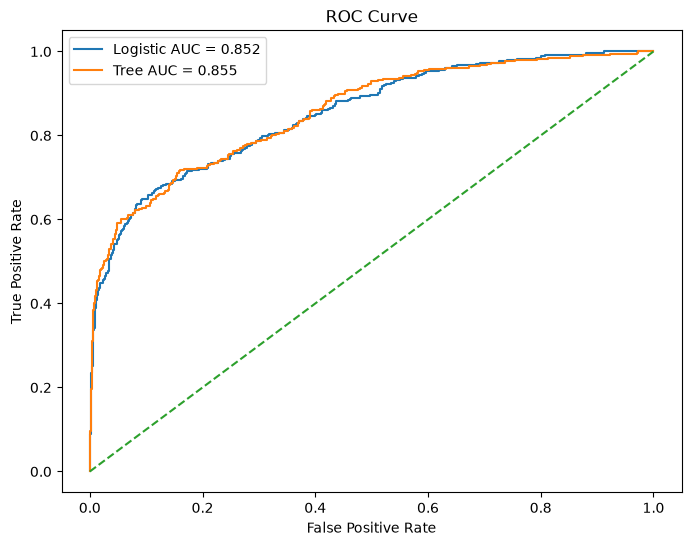

In [51]:
fpr_log, tpr_log, _ = roc_curve(
    y_test,
    logistic_prob
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test,
    tree_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic AUC = {logistic_auc:.3f}"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Tree AUC = {tree_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

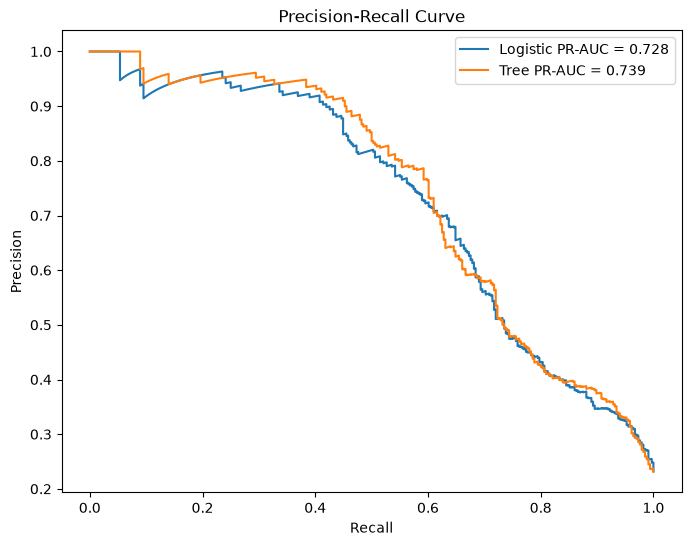

In [52]:
precision_log, recall_log, _ = precision_recall_curve(
    y_test,
    logistic_prob
)

precision_tree, recall_tree, _ = precision_recall_curve(
    y_test,
    tree_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_log,
    precision_log,
    label=f"Logistic PR-AUC = {logistic_pr_auc:.3f}"
)

plt.plot(
    recall_tree,
    precision_tree,
    label=f"Tree PR-AUC = {tree_pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

In [53]:
if tree_auc >= logistic_auc:
    final_model = tree_model
    final_prob = tree_prob
    final_model_name = "HistGradientBoosting"
else:
    final_model = logistic_model
    final_prob = logistic_prob
    final_model_name = "Logistic Regression"

print("Selected model:", final_model_name)

Selected model: HistGradientBoosting


In [54]:
decile_df = pd.DataFrame({
    "customer_id": feature_table.loc[
        X_test.index,
        "customer_id"
    ],
    "actual_churn": y_test,
    "churn_probability": final_prob
})

decile_df = decile_df.sort_values(
    "churn_probability",
    ascending=False
).reset_index(drop=True)

decile_df["decile"] = pd.qcut(
    decile_df.index,
    q=10,
    labels=False
) + 1

In [55]:
decile_summary = (
    decile_df
    .groupby("decile")
    .agg(
        customers=("customer_id", "count"),
        churners=("actual_churn", "sum"),
        churn_rate=("actual_churn", "mean"),
        avg_score=("churn_probability", "mean")
    )
    .reset_index()
)

overall_churn_rate = y_test.mean()

decile_summary["lift"] = (
    decile_summary["churn_rate"] /
    overall_churn_rate
)

decile_summary

,decile,customers,churners,churn_rate,avg_score,lift
0,1,145,135,0.931034,0.930760,4.017857
1,2,145,70,0.482759,0.545471,2.083333
2,3,145,37,0.255172,0.270650,1.101190
3,4,145,20,0.137931,0.171457,0.595238
4,5,145,26,0.179310,0.117157,0.773810
5,6,145,24,0.165517,0.078239,0.714286
6,7,145,10,0.068966,0.050423,0.297619
7,8,145,6,0.041379,0.031594,0.178571
8,9,145,4,0.027586,0.017432,0.119048
9,10,145,4,0.027586,0.007136,0.119048


In [56]:
decile_summary["cumulative_churners"] = (
    decile_summary["churners"].cumsum()
)

decile_summary["cumulative_customers"] = (
    decile_summary["customers"].cumsum()
)

total_churners = decile_summary["churners"].sum()

decile_summary["cumulative_capture_rate"] = (
    decile_summary["cumulative_churners"] /
    total_churners
)

decile_summary["population_percentage"] = (
    decile_summary["cumulative_customers"] /
    decile_summary["customers"].sum()
)

decile_summary

,decile,customers,churners,churn_rate,avg_score,lift,cumulative_churners,cumulative_customers,cumulative_capture_rate,population_percentage
0,1,145,135,0.931034,0.930760,4.017857,135,145,0.401786,0.1
1,2,145,70,0.482759,0.545471,2.083333,205,290,0.610119,0.2
2,3,145,37,0.255172,0.270650,1.101190,242,435,0.720238,0.3
3,4,145,20,0.137931,0.171457,0.595238,262,580,0.779762,0.4
4,5,145,26,0.179310,0.117157,0.773810,288,725,0.857143,0.5
5,6,145,24,0.165517,0.078239,0.714286,312,870,0.928571,0.6
6,7,145,10,0.068966,0.050423,0.297619,322,1015,0.958333,0.7
7,8,145,6,0.041379,0.031594,0.178571,328,1160,0.976190,0.8
8,9,145,4,0.027586,0.017432,0.119048,332,1305,0.988095,0.9
9,10,145,4,0.027586,0.007136,0.119048,336,1450,1.000000,1.0


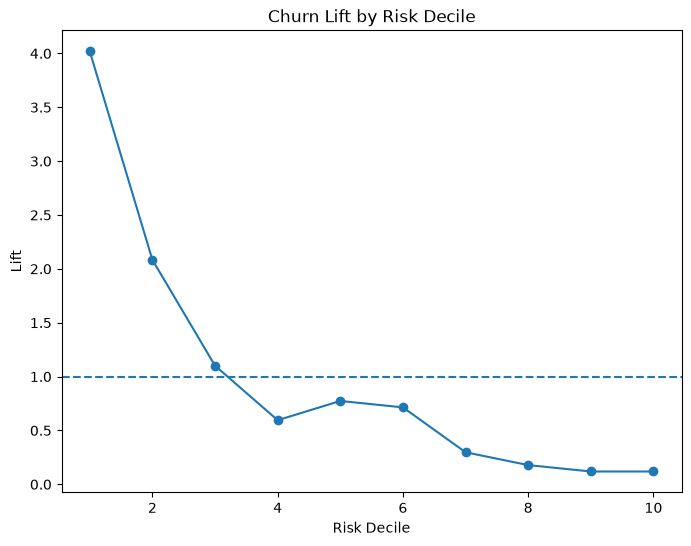

In [57]:
plt.figure(figsize=(8, 6))

plt.plot(
    decile_summary["decile"],
    decile_summary["lift"],
    marker="o"
)

plt.axhline(
    1,
    linestyle="--"
)

plt.xlabel("Risk Decile")
plt.ylabel("Lift")
plt.title("Churn Lift by Risk Decile")

plt.show()

In [58]:
top_decile = decile_df[
    decile_df["decile"] == 1
]

top_decile_precision = top_decile["actual_churn"].mean()

top_decile_churners = top_decile["actual_churn"].sum()

print(
    "Top decile customers:",
    len(top_decile)
)

print(
    "Top decile precision:",
    round(top_decile_precision, 4)
)

print(
    "Actual churners in top decile:",
    int(top_decile_churners)
)

Top decile customers: 145
Top decile precision: 0.931
Actual churners in top decile: 135


In [59]:
OFFER_COST = 40
CONVERSION_RATE = 0.25
RETAINED_CUSTOMER_VALUE = 900

expected_value_per_churner = (
    CONVERSION_RATE *
    RETAINED_CUSTOMER_VALUE
)

net_value_per_successful_target = (
    expected_value_per_churner -
    OFFER_COST
)

print(
    "Expected value per churner:",
    expected_value_per_churner
)

print(
    "Expected net value per targeted customer:",
    net_value_per_successful_target
)

Expected value per churner: 225.0
Expected net value per targeted customer: 185.0


In [60]:
economic_analysis = decile_summary.copy()

economic_analysis["offer_cost"] = (
    economic_analysis["customers"] *
    OFFER_COST
)

economic_analysis["expected_retained_customers"] = (
    economic_analysis["churners"] *
    CONVERSION_RATE
)

economic_analysis["expected_value"] = (
    economic_analysis["expected_retained_customers"] *
    RETAINED_CUSTOMER_VALUE
)

economic_analysis["expected_net_return"] = (
    economic_analysis["expected_value"] -
    economic_analysis["offer_cost"]
)

economic_analysis

,decile,customers,churners,churn_rate,avg_score,lift,cumulative_churners,cumulative_customers,cumulative_capture_rate,population_percentage,offer_cost,expected_retained_customers,expected_value,expected_net_return
0,1,145,135,0.931034,0.930760,4.017857,135,145,0.401786,0.1,5800,33.75,30375.0,24575.0
1,2,145,70,0.482759,0.545471,2.083333,205,290,0.610119,0.2,5800,17.50,15750.0,9950.0
2,3,145,37,0.255172,0.270650,1.101190,242,435,0.720238,0.3,5800,9.25,8325.0,2525.0
3,4,145,20,0.137931,0.171457,0.595238,262,580,0.779762,0.4,5800,5.00,4500.0,-1300.0
4,5,145,26,0.179310,0.117157,0.773810,288,725,0.857143,0.5,5800,6.50,5850.0,50.0
5,6,145,24,0.165517,0.078239,0.714286,312,870,0.928571,0.6,5800,6.00,5400.0,-400.0
6,7,145,10,0.068966,0.050423,0.297619,322,1015,0.958333,0.7,5800,2.50,2250.0,-3550.0
7,8,145,6,0.041379,0.031594,0.178571,328,1160,0.976190,0.8,5800,1.50,1350.0,-4450.0
8,9,145,4,0.027586,0.017432,0.119048,332,1305,0.988095,0.9,5800,1.00,900.0,-4900.0
9,10,145,4,0.027586,0.007136,0.119048,336,1450,1.000000,1.0,5800,1.00,900.0,-4900.0


In [61]:
best_decile = economic_analysis.loc[
    economic_analysis["expected_net_return"].idxmax()
]

best_decile

decile                             1.000000
customers                        145.000000
churners                         135.000000
churn_rate                         0.931034
avg_score                          0.930760
lift                               4.017857
cumulative_churners              135.000000
cumulative_customers             145.000000
cumulative_capture_rate            0.401786
population_percentage              0.100000
offer_cost                      5800.000000
expected_retained_customers       33.750000
expected_value                 30375.000000
expected_net_return            24575.000000
Name: 0, dtype: float64

In [62]:
threshold = top_decile["churn_probability"].min()

predicted_churn = (
    final_prob >= threshold
).astype(int)

cm = confusion_matrix(
    y_test,
    predicted_churn
)

cm

array([[1104,   10],
       [ 201,  135]])

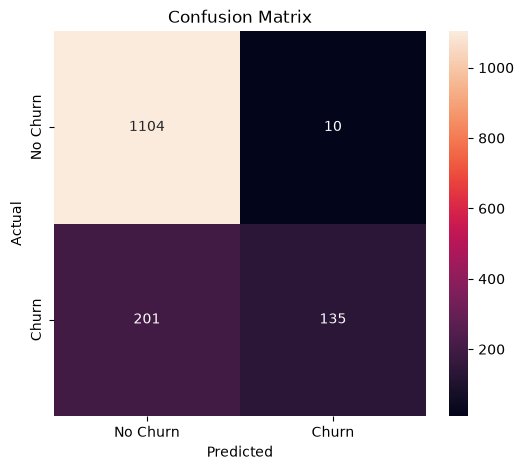

In [63]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [64]:
print(
    classification_report(
        y_test,
        predicted_churn,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.85      0.99      0.91      1114
       Churn       0.93      0.40      0.56       336

    accuracy                           0.85      1450
   macro avg       0.89      0.70      0.74      1450
weighted avg       0.87      0.85      0.83      1450



In [65]:
logistic_estimator = logistic_model.named_steps["model"]

logistic_coefficients = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": logistic_estimator.coef_[0]
})

logistic_coefficients["abs_coefficient"] = (
    logistic_coefficients["coefficient"]
    .abs()
)

logistic_coefficients = (
    logistic_coefficients
    .sort_values(
        "abs_coefficient",
        ascending=False
    )
)

logistic_coefficients.head(15)

,feature,coefficient,abs_coefficient
14,app_sessions_last_3m,-0.947399,0.947399
13,web_sessions_last_3m,-0.857410,0.857410
15,emails_received_last_3m,0.803467,0.803467
18,cart_abandonments_last_3m,-0.802226,0.802226
16,emails_opened_last_3m,-0.755782,0.755782
21,app_sessions_previous_3m,0.543601,0.543601
0,recency_days,0.514594,0.514594
40,transaction_lines,-0.485201,0.485201
4,orders_last_90d,0.473319,0.473319
19,wishlist_adds_last_3m,-0.472865,0.472865


In [66]:
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
})

importance_df = importance_df.sort_values(
    "importance_mean",
    ascending=False
)

importance_df.head(15)

,feature,importance_mean,importance_std
18,cart_abandonments_last_3m,0.026138,0.005384
13,web_sessions_last_3m,0.016042,0.003378
19,wishlist_adds_last_3m,0.012641,0.002862
0,recency_days,0.012229,0.002201
29,email_open_rate,0.007812,0.002393
14,app_sessions_last_3m,0.007725,0.001849
47,tenure_months,0.005721,0.001052
15,emails_received_last_3m,0.003560,0.001922
16,emails_opened_last_3m,0.002772,0.001298
10,basket_size_last_90d,0.001614,0.000581


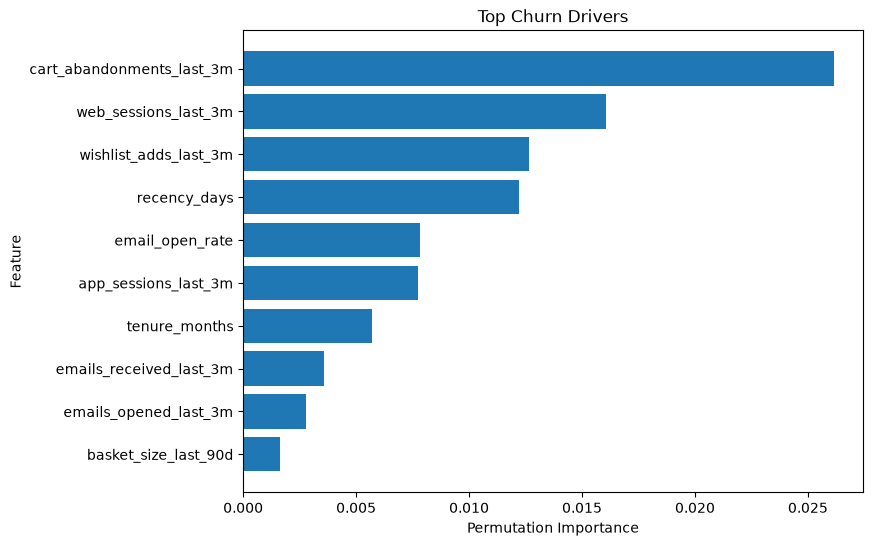

In [67]:
top_importance = importance_df.head(10).sort_values(
    "importance_mean"
)

plt.figure(figsize=(8, 6))

plt.barh(
    top_importance["feature"],
    top_importance["importance_mean"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top Churn Drivers")

plt.show()

In [68]:
# Top 10 churn drivers from permutation importance

top_drivers = importance_df.head(10).copy()

def classify_actionability(feature):
    
    # Highly actionable through marketing / engagement
    if any(x in feature for x in [
        "cart_abandonments",
        "web_sessions",
        "app_sessions",
        "wishlist_adds",
        "email_open",
        "email_click",
        "emails_received"
    ]):
        return "Actionable"
    
    # Partially actionable through service / operations
    elif any(x in feature for x in [
        "ticket",
        "csat",
        "response",
        "resolution",
        "delivery",
        "returned"
    ]):
        return "Actionable"
    
    # Commercially actionable
    elif any(x in feature for x in [
        "discount",
        "spend_trend",
        "order_frequency_trend",
        "basket_size_trend"
    ]):
        return "Actionable"
    
    # Mostly descriptive rather than directly controllable
    elif any(x in feature for x in [
        "age",
        "tenure",
        "household",
        "gender"
    ]):
        return "Non-actionable"
    
    # RFM / behavioural indicators
    elif any(x in feature for x in [
        "recency",
        "frequency",
        "monetary",
        "aov"
    ]):
        return "Indirectly actionable"
    
    else:
        return "Review"

top_drivers["actionability"] = (
    top_drivers["feature"]
    .apply(classify_actionability)
)

top_drivers[
    ["feature", "importance_mean", "actionability"]
]

,feature,importance_mean,actionability
18,cart_abandonments_last_3m,0.026138,Actionable
13,web_sessions_last_3m,0.016042,Actionable
19,wishlist_adds_last_3m,0.012641,Actionable
0,recency_days,0.012229,Indirectly actionable
29,email_open_rate,0.007812,Actionable
14,app_sessions_last_3m,0.007725,Actionable
47,tenure_months,0.005721,Non-actionable
15,emails_received_last_3m,0.003560,Actionable
16,emails_opened_last_3m,0.002772,Review
10,basket_size_last_90d,0.001614,Review


In [69]:
print("TOP 5 CHURN DRIVERS")
print("=" * 50)

for i, row in top_drivers.head(5).iterrows():
    print(
        f"{row['feature']}: "
        f"{row['importance_mean']:.4f} "
        f"→ {row['actionability']}"
    )

TOP 5 CHURN DRIVERS
cart_abandonments_last_3m: 0.0261 → Actionable
web_sessions_last_3m: 0.0160 → Actionable
wishlist_adds_last_3m: 0.0126 → Actionable
recency_days: 0.0122 → Indirectly actionable
email_open_rate: 0.0078 → Actionable


## Churn Driver Interpretation

The permutation importance analysis shows that recent digital engagement
features are the strongest predictors of churn.

The most important feature is `cart_abandonments_last_3m`, followed by
`web_sessions_last_3m` and `wishlist_adds_last_3m`. This indicates that
customers showing recent digital shopping intent without completing purchases
are more strongly associated with future churn risk.

`recency_days` is also an important predictor, indicating that customers who
have gone longer without purchasing are at higher risk.

`email_open_rate` provides an additional engagement signal, suggesting that
declining interaction with marketing communication can help identify
customers at risk.

Most of the top drivers are actionable because marketing can respond through
cart-recovery campaigns, personalized product recommendations, targeted
offers, and engagement campaigns.

Recency is less directly controllable because it describes customer
behaviour, but it can be used as an early-warning signal for retention
interventions.

In [72]:
# Create customer-level scores ONLY for the test set

customer_scores = feature_table.loc[
    X_test.index,
    ["customer_id", "churned"]
].copy()

customer_scores["churn_probability"] = final_prob

customer_scores = customer_scores.sort_values(
    "churn_probability",
    ascending=False
).reset_index(drop=True)

customer_scores.head(10)

,customer_id,churned,churn_probability
0,CUST101332,1,0.990547
1,CUST104249,1,0.988011
2,CUST107596,1,0.986789
3,CUST103692,1,0.985492
4,CUST102914,1,0.985384
5,CUST102688,1,0.983242
6,CUST107568,1,0.983110
7,CUST103211,1,0.982316
8,CUST109636,1,0.981978
9,CUST102289,1,0.981182


In [73]:
example_customer_id = customer_scores.iloc[0]["customer_id"]

example_probability = customer_scores.iloc[0]["churn_probability"]

print("Example customer:", example_customer_id)
print(
    "Churn probability:",
    f"{example_probability:.2%}"
)

Example customer: CUST101332
Churn probability: 99.05%


In [74]:
example_customer = feature_table[
    feature_table["customer_id"] == example_customer_id
].copy()

example_customer.T

,787
customer_id,CUST101332
churned,1
last_order_datetime,2025-12-02 15:14:00
recency_days,149.365266
frequency,13
monetary,1480.41
average_order_value,113.877692
orders_last_90d,0.0
orders_previous_90d,1.0
order_frequency_trend,0.0


In [75]:
# Top 5 globally important features

top_5_features = importance_df.head(5)["feature"].tolist()

comparison = []

for feature in top_5_features:

    customer_value = example_customer[feature].iloc[0]
    population_median = feature_table[feature].median()

    importance_value = importance_df.loc[
        importance_df["feature"] == feature,
        "importance_mean"
    ].iloc[0]

    comparison.append({
        "feature": feature,
        "customer_value": customer_value,
        "population_median": population_median,
        "importance": importance_value
    })

customer_explanation = pd.DataFrame(comparison)

customer_explanation

,feature,customer_value,population_median,importance
0,cart_abandonments_last_3m,0.000000,2.000000,0.026138
1,web_sessions_last_3m,0.000000,11.000000,0.016042
2,wishlist_adds_last_3m,0.000000,1.000000,0.012641
3,recency_days,149.365266,21.211100,0.012229
4,email_open_rate,0.000000,0.363636,0.007812


In [77]:
final_scores = customer_scores[
    ["customer_id", "churned"]
].copy()

final_scores["churn_probability"] = final_prob

final_scores["risk_decile"] = pd.qcut(
    final_scores["churn_probability"].rank(
        method="first"
    ),
    q=10,
    labels=False
) + 1

final_scores["high_risk"] = (
    final_scores["churn_probability"] >= threshold
).astype(int)

final_scores = final_scores.sort_values(
    "churn_probability",
    ascending=False
)

final_scores.head()

,customer_id,churned,churn_probability,risk_decile,high_risk
125,CUST104054,1,0.990547,10,1
808,CUST109136,1,0.988011,10,1
1426,CUST106355,0,0.986789,10,1
864,CUST104002,0,0.985492,10,1
258,CUST102670,0,0.985384,10,1


In [78]:
final_scores.to_csv(
    PROCESSED_DATA_PATH / "customer_churn_scores.csv",
    index=False
)

feature_table.to_csv(
    PROCESSED_DATA_PATH / "churn_model_features.csv",
    index=False
)

model_comparison.to_csv(
    TABLES_PATH / "churn_model_comparison.csv",
    index=False
)

decile_summary.to_csv(
    TABLES_PATH / "churn_decile_lift.csv",
    index=False
)

economic_analysis.to_csv(
    TABLES_PATH / "churn_economic_analysis.csv",
    index=False
)

importance_df.to_csv(
    TABLES_PATH / "churn_feature_importance.csv",
    index=False
)

print("Churn outputs saved successfully.")

Churn outputs saved successfully.


In [79]:
print("=" * 70)
print("NOTEBOOK 03 VALIDATION")
print("=" * 70)

print(f"Eligible customers:       {len(feature_table):,}")
print(f"Features before encoding: {X.shape[1]:,}")
print(f"Encoded features:         {X_encoded.shape[1]:,}")
print(f"Churn rate:               {y.mean():.2%}")
print("-" * 70)

print(f"Final model:              {final_model_name}")
print(f"ROC-AUC:                  {roc_auc_score(y_test, final_prob):.4f}")
print(f"PR-AUC:                   {average_precision_score(y_test, final_prob):.4f}")
print("-" * 70)

print(
    f"Top-decile precision:     "
    f"{top_decile_precision:.2%}"
)

print(
    f"Top-decile churners:      "
    f"{int(top_decile_churners):,}"
)

print(
    f"Selected threshold:       "
    f"{threshold:.4f}"
)

print("-" * 70)
print("Saved files:")
print("- customer_churn_scores.csv")
print("- churn_model_features.csv")
print("- churn_model_comparison.csv")
print("- churn_decile_lift.csv")
print("- churn_economic_analysis.csv")
print("- churn_feature_importance.csv")

print("=" * 70)
print("Notebook 03 completed.")
print("=" * 70)

NOTEBOOK 03 VALIDATION
Eligible customers:       7,247
Features before encoding: 51
Encoded features:         59
Churn rate:               23.15%
----------------------------------------------------------------------
Final model:              HistGradientBoosting
ROC-AUC:                  0.8552
PR-AUC:                   0.7395
----------------------------------------------------------------------
Top-decile precision:     93.10%
Top-decile churners:      135
Selected threshold:       0.8066
----------------------------------------------------------------------
Saved files:
- customer_churn_scores.csv
- churn_model_features.csv
- churn_model_comparison.csv
- churn_decile_lift.csv
- churn_economic_analysis.csv
- churn_feature_importance.csv
Notebook 03 completed.


In [81]:
feature_table.shape


(7247, 54)

In [87]:
# ============================================================
# ALL 7,247 ACTIVE CUSTOMERS
# ============================================================

active_customers = feature_table.copy()

X_active = active_customers.drop(
    columns=["customer_id", "churned"]
)

print("Active customers:", len(active_customers))
print("Raw feature shape:", X_active.shape)

Active customers: 7247
Raw feature shape: (7247, 52)


In [89]:
[name for name in globals() if "enc" in name.lower() or "prep" in name.lower()]

['frequency', 'X_encoded']

In [90]:
print(X_encoded.shape)

(7247, 59)


In [91]:
# ============================================================
# PREDICT ALL 7,247 ACTIVE CUSTOMERS
# ============================================================

active_prob = final_model.predict_proba(
    X_encoded
)[:, 1]

print("Customers:", len(X_encoded))
print("Predictions:", len(active_prob))

Customers: 7247
Predictions: 7247


In [92]:
active_scores = feature_table[
    ["customer_id"]
].copy()

active_scores["churn_probability"] = active_prob

In [93]:
active_scores["risk_decile"] = pd.qcut(
    active_scores["churn_probability"].rank(
        method="first"
    ),
    q=10,
    labels=False
) + 1

active_scores["high_risk"] = (
    active_scores["churn_probability"] >= threshold
).astype(int)

active_scores = active_scores.sort_values(
    "churn_probability",
    ascending=False
).reset_index(drop=True)

active_scores.head(10)

,customer_id,churn_probability,risk_decile,high_risk
0,CUST108559,0.992616,10,1
1,CUST106245,0.992122,10,1
2,CUST108698,0.991907,10,1
3,CUST104368,0.991673,10,1
4,CUST103440,0.991342,10,1
5,CUST104588,0.991040,10,1
6,CUST101332,0.990547,10,1
7,CUST110581,0.990534,10,1
8,CUST103857,0.989615,10,1
9,CUST100083,0.989594,10,1


In [94]:
# ============================================================
# VERIFY ALL ACTIVE CUSTOMER PREDICTIONS
# ============================================================

print("=" * 70)
print("ACTIVE CUSTOMER CHURN PREDICTION VALIDATION")
print("=" * 70)

print(f"Active customers:        {len(active_scores):,}")
print(f"Predictions:             {active_scores['churn_probability'].notna().sum():,}")

print("-" * 70)

print(
    f"Probability minimum:     "
    f"{active_scores['churn_probability'].min():.4f}"
)

print(
    f"Probability maximum:     "
    f"{active_scores['churn_probability'].max():.4f}"
)

print(
    f"Probability mean:        "
    f"{active_scores['churn_probability'].mean():.4f}"
)

print("-" * 70)

print("Risk decile distribution:")
print(
    active_scores["risk_decile"]
    .value_counts()
    .sort_index()
)

print("-" * 70)

print("High-risk customers:")
print(
    active_scores["high_risk"].value_counts()
)

print("-" * 70)

print("Top 10 highest-risk customers:")
print(
    active_scores.head(10)
)

print("=" * 70)

ACTIVE CUSTOMER CHURN PREDICTION VALIDATION
Active customers:        7,247
Predictions:             7,247
----------------------------------------------------------------------
Probability minimum:     0.0011
Probability maximum:     0.9926
Probability mean:        0.2296
----------------------------------------------------------------------
Risk decile distribution:
risk_decile
1     725
2     725
3     724
4     725
5     725
6     724
7     725
8     724
9     725
10    725
Name: count, dtype: int64
----------------------------------------------------------------------
High-risk customers:
high_risk
0    6451
1     796
Name: count, dtype: int64
----------------------------------------------------------------------
Top 10 highest-risk customers:
  customer_id  churn_probability  risk_decile  high_risk
0  CUST108559           0.992616           10          1
1  CUST106245           0.992122           10          1
2  CUST108698           0.991907           10          1
3  CUST104368 

In [96]:
# ============================================================
# SAVE ALL ACTIVE CUSTOMER CHURN PREDICTIONS
# ============================================================

active_scores.to_csv(
    PROCESSED_DATA_PATH / "active_customer_churn_predictions.csv",
    index=False
)

print(
    f"Saved {len(active_scores):,} active customer predictions."
)

Saved 7,247 active customer predictions.


In [97]:
print(
    active_scores[
        ["customer_id", "churn_probability", "risk_decile", "high_risk"]
    ].head(10)
)

  customer_id  churn_probability  risk_decile  high_risk
0  CUST108559           0.992616           10          1
1  CUST106245           0.992122           10          1
2  CUST108698           0.991907           10          1
3  CUST104368           0.991673           10          1
4  CUST103440           0.991342           10          1
5  CUST104588           0.991040           10          1
6  CUST101332           0.990547           10          1
7  CUST110581           0.990534           10          1
8  CUST103857           0.989615           10          1
9  CUST100083           0.989594           10          1
